# 06 · Square-lattice J₁-J₂: benchmarks, partons and neural quantum states

**What you will learn**
1. The 4×4 benchmark ($E_0=-11.228483$), Néel order and the frustrated regime around $J_2\approx0.5$.
2. The π-flux state, built with the exact Gutzwiller projection and with VMC (the two agree).
3. Neural quantum states (RBM + stochastic reconfiguration), with and without the Marshall sign rule. Frustration makes the sign structure hard to learn.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import qslab
from qslab import lattice, models, ED
from qslab.parton import SpinonAnsatz, projected_state, GutzwillerVMC
from qslab.nqs import NQS

## 1. ED: energy, Néel structure factor and dimer correlations versus J₂

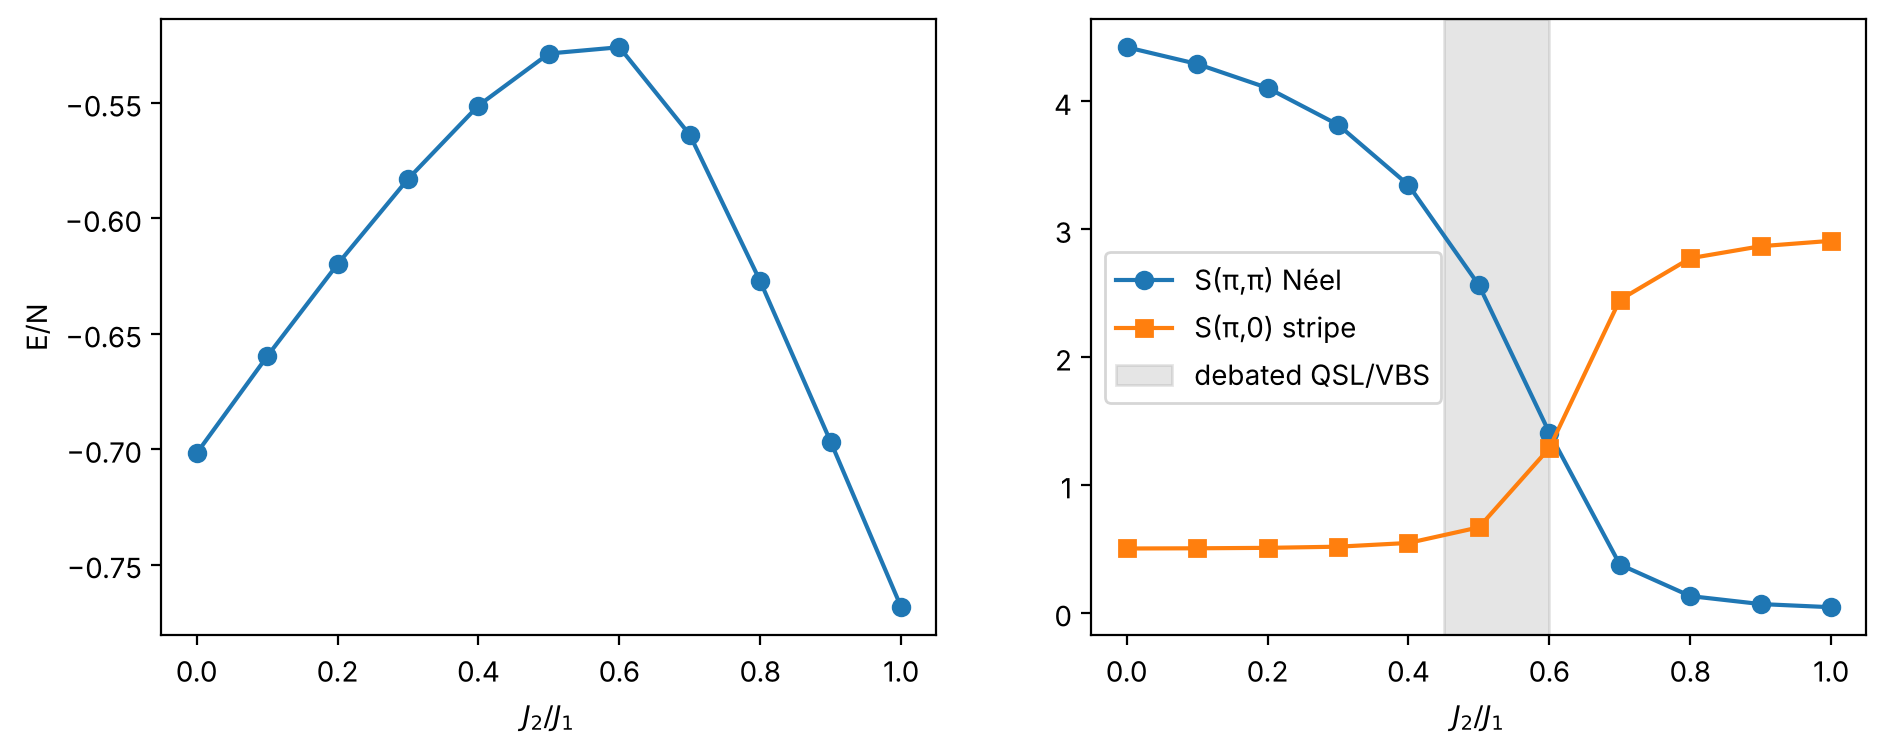

J2=0 E0 = -11.228483208428878


In [2]:
lat = lattice.square(4)
def obs(J2):
    ed = ED(models.j1j2_square(lat, J2=J2), 16)
    w, v = ed.diagonalize(k=3)
    psi = v[:, 0]; C = ed.spin_correlations(psi)
    Spp = ed.structure_factor(psi, lat.positions, np.array([np.pi, np.pi]), C=C)[0]
    Sp0 = ed.structure_factor(psi, lat.positions, np.array([np.pi, 0]), C=C)[0]
    return w[0] / 16, Spp, Sp0, w[1] - w[0]
J2s = np.linspace(0, 1, 11)
R = np.array(qslab.pmap(obs, J2s))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(J2s, R[:, 0], "o-"); ax[0].set_ylabel("E/N")
ax[1].plot(J2s, R[:, 1], "o-", label="S(π,π) Néel"); ax[1].plot(J2s, R[:, 2], "s-", label="S(π,0) stripe")
ax[1].axvspan(0.45, 0.6, color="gray", alpha=0.2, label="debated QSL/VBS")
for a in ax: a.set_xlabel("$J_2/J_1$")
ax[1].legend(); plt.show()
print("J2=0 E0 =", R[0, 0] * 16)

## 2. Partons: uniform RVB and π flux
Antiperiodic spinon boundary conditions (`twist=(0, π)`) close the Fermi shell. The exact projection and VMC must agree.

In [3]:
ed = ED(models.heisenberg(lat), 16); E0, g = ed.ground_state()
for name, fl in [("uniform RVB", {"square": 0.0}), ("π flux", {"square": np.pi})]:
    ans = SpinonAnsatz.from_flux(lat, fl, twist=(0, np.pi))
    basis, psi = projected_state(ans)
    E_ex = np.vdot(psi, ed.matvec(psi)).real / 16
    r = GutzwillerVMC(ans).run(n_sweeps=1500, n_therm=100, n_chains=2)
    print(f"{name:12s}: exact projection {E_ex:.5f} | VMC {r['E_per_site']:.5f} ± {r['err_per_site']:.5f} "
          f"| overlap {abs(np.vdot(g, psi)):.3f}")

uniform RVB : exact projection -0.57231 | VMC -0.56948 ± 0.00195 | overlap 0.780


π flux      : exact projection -0.63773 | VMC -0.63687 ± 0.00039 | overlap 0.846


Larger π-flux lattices. The energy per site converges quickly with size; compare it with the 4×4 exact value above and with the exact ground state ($\approx -0.6694$ in the thermodynamic limit). A plain projected Fermi sea is a decent but not optimal variational state for the Néel phase.

In [4]:
for L in [8, 12]:
    ans = SpinonAnsatz.from_flux(lattice.square(L), {"square": np.pi}, twist=(0, np.pi))
    r = GutzwillerVMC(ans).run(n_sweeps=300, n_therm=50, n_chains=2)
    print(f"L={L}: E/N = {r['E_per_site']:.4f} ± {r['err_per_site']:.4f}")

L=8: E/N = -0.6273 ± 0.0000


L=12: E/N = -0.6274 ± 0.0002


## 3. Neural quantum states
A complex RBM optimised with stochastic reconfiguration, using exact sums over the $S^z=0$ sector (no sampling noise).
Run it at $J_2=0$ (unfrustrated) and $J_2=0.5$ (frustrated), with and without the Marshall sign.

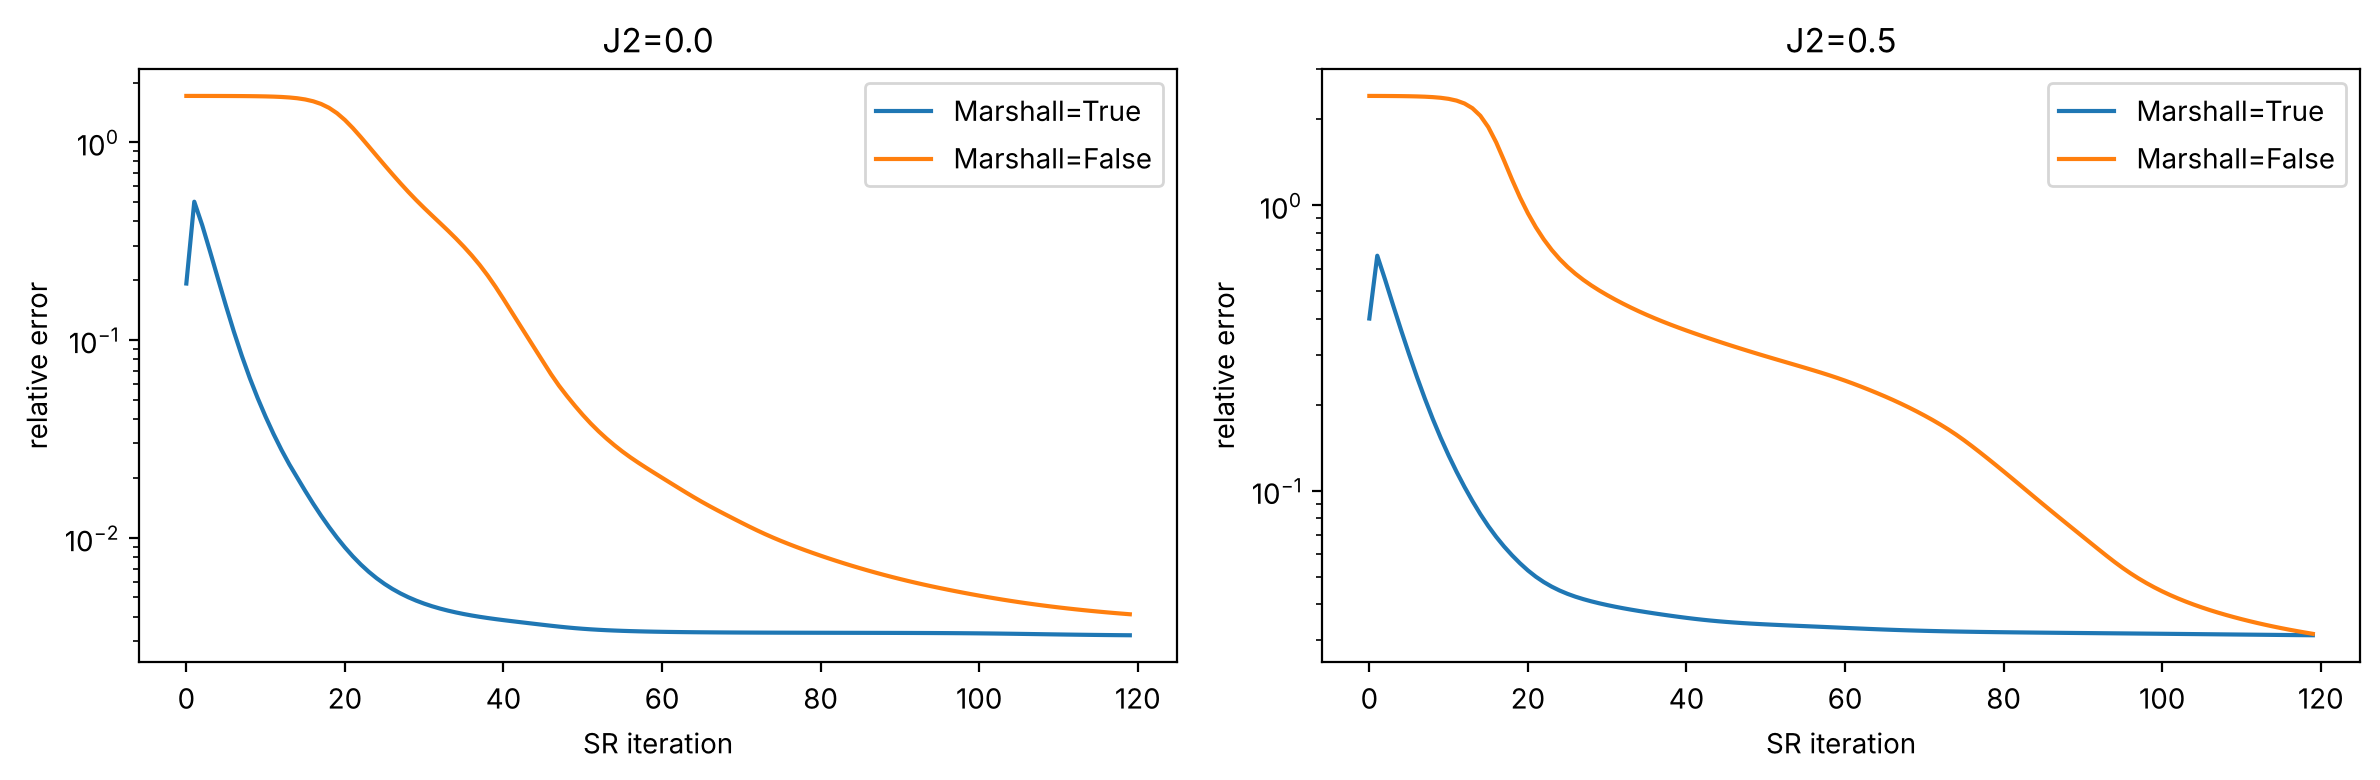

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, J2 in enumerate([0.0, 0.5]):
    H = models.j1j2_square(lat, J2=J2); Eex = ED(H, 16).ground_state()[0]
    for marsh in [True, False]:
        q = NQS(H, 16, alpha=1, marshall=lat.sublattice_sign() if marsh else None, seed=1)
        q.optimize(120, lr=0.05, verbose=0)
        err = [(e - Eex) / abs(Eex) for e, _ in q.history]
        ax[n].semilogy(np.abs(err), label=f"Marshall={marsh}")
    ax[n].set_title(f"J2={J2}"); ax[n].set_xlabel("SR iteration"); ax[n].set_ylabel("relative error"); ax[n].legend()
plt.tight_layout(); plt.show()

For bigger systems use `NQS(..., sampler='metropolis')`. Under `mpirun` every rank samples independent chains,
and gradients and the S matrix are averaged with `allreduce`.

## Quiz

In [6]:
from qslab import quiz
quiz.show("square_j1j2")

=== Square J1-J2 model and benchmarks ===


Q1. [numeric] ED ground-state energy per site of the 4x4 Heisenberg AFM (J2 = 0)?
    -> numeric answer (tolerance 1e-05)

Q2. [numeric] Same at the maximally frustrated point J2 = 0.5?
    -> numeric answer (tolerance 1e-05)

Q3. [numeric] Exact energy per site of the Gutzwiller-projected pi-flux state on 4x4 (antiperiodic spinon BCs)?
    -> numeric answer (tolerance 0.0002)

Q4. [mcq] Why does an RBM need the Marshall sign on the square lattice but struggles on kagome?
    (a) The bipartite AFM ground state has a known sign rule; frustrated lattices do not
    (b) RBMs cannot be complex
    (c) Because of Sz conservation
    (d) No reason

Q5. [mcq] Which phase is believed to lie at 0.45 < J2 < 0.6?
    (a) ferromagnet
    (b) toric code
    (c) 120-degree order
    (d) gapless spin liquid and/or plaquette VBS (debated)

